###Import Libarary

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression



##Load Data

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/spam (4).csv', encoding='ISO-8859-1')

In [ ]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [ ]:
df=df[['v1','v2']]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
df.shape

(5572, 2)

In [ ]:
df.describe()

,v1,v2
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [ ]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.rename(columns = {"v1":"Target", "v2":"Text"}, inplace = True)


In [ ]:
df.head()

,Target,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


###Visualization

<Axes: xlabel='Target', ylabel='count'>

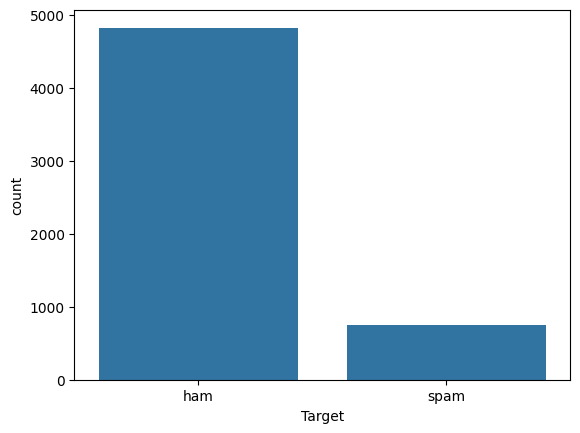

In [ ]:
sns.countplot(x= df["Target"])


###Data Cleaning

In [ ]:
df.duplicated().sum()

np.int64(403)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.isnull().sum()

,0
Target,0
Text,0


In [ ]:
df['Text'] = df['Text'].apply(lambda x: re.sub('[^a-zA-Z]', ' ', x))

In [ ]:
df['Text']=df['Text'].apply(lambda x: x.lower())

In [ ]:
df['Text'] = df['Text'].apply(lambda x: x.split())


In [ ]:
df['Text'] = df['Text'].apply(lambda x: ' '.join(x))

In [ ]:
df.head()

,Target,Text
0,ham,go until jurong point crazy available only in ...
1,ham,ok lar joking wif u oni
2,spam,free entry in a wkly comp to win fa cup final ...
3,ham,u dun say so early hor u c already then say
4,ham,nah i don t think he goes to usf he lives arou...


###Tokanization

In [ ]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
df['tokin']=df.apply(lambda row: nltk.word_tokenize(row['Text']), axis=1)

In [ ]:
df.head()

,Target,Text,tokin
0,ham,go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o..."
1,ham,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]"
2,spam,free entry in a wkly comp to win fa cup final ...,"[free, entry, in, a, wkly, comp, to, win, fa, ..."
3,ham,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t..."
4,ham,nah i don t think he goes to usf he lives arou...,"[nah, i, don, t, think, he, goes, to, usf, he,..."


###Remove stop word

In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
stop_words = set(stopwords.words("english"))
df["Nostopword_Text"] = df["tokin"].apply(
    lambda text: [word for word in text if word not in stop_words]
)

In [ ]:
df.head()

,Target,Text,tokin,Nostopword_Text
0,ham,go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o...","[go, jurong, point, crazy, available, bugis, n..."
1,ham,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,spam,free entry in a wkly comp to win fa cup final ...,"[free, entry, in, a, wkly, comp, to, win, fa, ...","[free, entry, wkly, comp, win, fa, cup, final,..."
3,ham,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t...","[u, dun, say, early, hor, u, c, already, say]"
4,ham,nah i don t think he goes to usf he lives arou...,"[nah, i, don, t, think, he, goes, to, usf, he,...","[nah, think, goes, usf, lives, around, though]"


###Lemmatization

In [ ]:
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
lemtiz=WordNetLemmatizer()
df['Lemmatization']=df['Nostopword_Text'].apply(lambda x: [lemtiz.lemmatize(word) for word in x])

In [ ]:
df.head()

,Target,Text,tokin,Nostopword_Text,Lemmatization
0,ham,go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o...","[go, jurong, point, crazy, available, bugis, n...","[go, jurong, point, crazy, available, bugis, n..."
1,ham,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,spam,free entry in a wkly comp to win fa cup final ...,"[free, entry, in, a, wkly, comp, to, win, fa, ...","[free, entry, wkly, comp, win, fa, cup, final,...","[free, entry, wkly, comp, win, fa, cup, final,..."
3,ham,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t...","[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, early, hor, u, c, already, say]"
4,ham,nah i don t think he goes to usf he lives arou...,"[nah, i, don, t, think, he, goes, to, usf, he,...","[nah, think, goes, usf, lives, around, though]","[nah, think, go, usf, life, around, though]"


###vectorize

In [ ]:
corpus=df['Lemmatization'].apply(lambda x: ' '.join(x))
corpus

,Lemmatization
0,go jurong point crazy available bugis n great ...
1,ok lar joking wif u oni
2,free entry wkly comp win fa cup final tkts st ...
3,u dun say early hor u c already say
4,nah think go usf life around though
...,...
5567,nd time tried contact u u pound prize claim ea...
5568,b going esplanade fr home
5569,pity mood suggestion
5570,guy bitching acted like interested buying some...


###Tidif

In [ ]:
tidif=TfidfVectorizer()

In [ ]:
x=tidif.fit_transform(corpus).toarray()

In [ ]:
x

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
l_encoder=LabelEncoder()

In [ ]:
df['Target']=l_encoder.fit_transform(df['Target'])

In [ ]:
df.head()

,Target,Text,tokin,Nostopword_Text,Lemmatization
0,0,go until jurong point crazy available only in ...,"[go, until, jurong, point, crazy, available, o...","[go, jurong, point, crazy, available, bugis, n...","[go, jurong, point, crazy, available, bugis, n..."
1,0,ok lar joking wif u oni,"[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]","[ok, lar, joking, wif, u, oni]"
2,1,free entry in a wkly comp to win fa cup final ...,"[free, entry, in, a, wkly, comp, to, win, fa, ...","[free, entry, wkly, comp, win, fa, cup, final,...","[free, entry, wkly, comp, win, fa, cup, final,..."
3,0,u dun say so early hor u c already then say,"[u, dun, say, so, early, hor, u, c, already, t...","[u, dun, say, early, hor, u, c, already, say]","[u, dun, say, early, hor, u, c, already, say]"
4,0,nah i don t think he goes to usf he lives arou...,"[nah, i, don, t, think, he, goes, to, usf, he,...","[nah, think, goes, usf, lives, around, though]","[nah, think, go, usf, life, around, though]"


###Model

In [ ]:
y=df['Target']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [ ]:
classifiers = [RandomForestClassifier(),
               KNeighborsClassifier(),
               SVC(),
               MultinomialNB(),
               LogisticRegression(),
               DecisionTreeClassifier()]

In [ ]:
for c in classifiers:
    c.fit(x_train, y_train)

###ِAccuracy Report

In [ ]:
for model in classifiers:
    y_pred = model.predict(x_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{type(model).__name__}: {accuracy * 100:.2f}%")


RandomForestClassifier: 97.39%
KNeighborsClassifier: 90.72%
SVC: 96.81%
MultinomialNB: 96.23%
LogisticRegression: 95.84%
DecisionTreeClassifier: 95.26%


In [ ]:
# ============================================
# SMS SPAM DETECTOR - STREAMLIT APPLICATION
# Google Colab | Dark Blue Theme
# ============================================

import os
import sys
import time
import pickle
import subprocess

# 1. Install required packages
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "streamlit", "plotly"],
    check=True
)

# 2. Verify trained objects
if "classifiers" not in globals():
    raise ValueError(
        "The trained classifiers were not found. "
        "Run your model-training cell first."
    )

if "tidif" not in globals():
    raise ValueError(
        "The fitted TF-IDF vectorizer was not found. "
        "Run your TF-IDF cell first."
    )

rf_model = classifiers[0]

# Save actual fitted objects
with open("/content/rf_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

with open("/content/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tidif, f)

print("Trained model and TF-IDF vectorizer saved.")

# 3. Create Streamlit application
app_code = r'''
import streamlit as st
import pickle
import re
import nltk
import pandas as pd
import plotly.graph_objects as go

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

st.set_page_config(
    page_title="SMS Spam Detector",
    page_icon="🛡️",
    layout="wide"
)

# Download required language resources
for resource, path in [
    ("stopwords", "corpora/stopwords"),
    ("wordnet", "corpora/wordnet"),
]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(resource, quiet=True)

# Dark blue theme
st.markdown("""
<style>
.stApp {
    background: #071426;
    color: #F1F5F9;
}
section[data-testid="stSidebar"] {
    background: #0B1F3A;
    border-right: 1px solid #1E3A5F;
}
h1, h2, h3, p, label {
    color: #F1F5F9;
}
div.stButton > button {
    background: #1D4ED8;
    color: white;
    border: 1px solid #3B82F6;
    border-radius: 10px;
    padding: 8px 18px;
    font-weight: 600;
}
div.stButton > button:hover {
    background: #3B82F6;
    color: white;
}
textarea {
    background: #0B1F3A !important;
    color: #F1F5F9 !important;
}
.metric-card {
    background: #102A4C;
    border: 1px solid #1E3A5F;
    border-radius: 14px;
    padding: 22px;
    text-align: center;
    margin-bottom: 15px;
}
.metric-value {
    font-size: 25px;
    font-weight: bold;
    color: #60A5FA;
}
.metric-label {
    color: #CBD5E1;
    margin-top: 8px;
}
.result-card {
    padding: 24px;
    border-radius: 14px;
    text-align: center;
    margin-top: 20px;
}
.spam {
    background: #351B2A;
    border: 2px solid #F87171;
    color: #FCA5A5;
}
.ham {
    background: #10352F;
    border: 2px solid #34D399;
    color: #6EE7B7;
}
</style>
""", unsafe_allow_html=True)

# Load actual trained objects
@st.cache_resource
def load_model():
    with open("/content/rf_model.pkl", "rb") as f:
        model = pickle.load(f)

    with open("/content/tfidf_vectorizer.pkl", "rb") as f:
        vectorizer = pickle.load(f)

    return model, vectorizer

try:
    model, vectorizer = load_model()
except Exception as e:
    st.error("Could not load the trained model or TF-IDF vectorizer.")
    st.code(str(e))
    st.stop()

# Match the notebook preprocessing:
# regex cleaning -> lowercase -> split -> remove stopwords
# -> lemmatize -> join
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_message(message):
    message = re.sub(r"[^a-zA-Z]", " ", message)
    message = message.lower()
    words = message.split()

    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

# Sidebar
st.sidebar.markdown("# 🛡️ SMS Detector")
st.sidebar.write("Machine Learning Spam Classification")
page = st.sidebar.radio(
    "Navigation",
    ["Home & Analyzer", "Model Performance", "About Project"]
)

if page == "Home & Analyzer":
    st.title("🛡️ Intelligent SMS Spam Detection")
    st.write(
        "Analyze text messages using your trained Machine Learning model."
    )

    c1, c2, c3 = st.columns(3)

    with c1:
        st.markdown("""
        <div class="metric-card">
            <div class="metric-value">Random Forest</div>
            <div class="metric-label">Selected Model</div>
        </div>
        """, unsafe_allow_html=True)

    with c2:
        st.markdown("""
        <div class="metric-card">
            <div class="metric-value">97.39%</div>
            <div class="metric-label">Measured Test Accuracy</div>
        </div>
        """, unsafe_allow_html=True)

    with c3:
        st.markdown("""
        <div class="metric-card">
            <div class="metric-value">Spam / Ham</div>
            <div class="metric-label">Classification Classes</div>
        </div>
        """, unsafe_allow_html=True)

    st.divider()
    st.subheader("✉️ Message Analyzer")

    examples = {
        "Spam example": (
            "Congratulations! You have won a free prize. "
            "Click here to claim your reward now!"
        ),
        "Normal message example": (
            "Hey, are we still meeting tomorrow at 5 PM?"
        )
    }

    example_choice = st.selectbox(
        "Try an example",
        ["Write my own message"] + list(examples.keys())
    )

    default_text = examples.get(example_choice, "")

    message = st.text_area(
        "Enter your SMS message",
        value=default_text,
        height=150,
        placeholder="Type or paste your message here..."
    )

    st.caption(
        f"Characters: {len(message)} | Words: {len(message.split())}"
    )

    if st.button("🔍 Analyze Message", use_container_width=True):
        if not message.strip():
            st.warning("Please enter a message first.")
        else:
            try:
                cleaned = preprocess_message(message)
                features = vectorizer.transform([cleaned])
                prediction = model.predict(features)[0]

                # The notebook label encoder maps ham=0 and spam=1
                if prediction == 1:
                    st.markdown("""
                    <div class="result-card spam">
                        <h2>🚨 SPAM DETECTED</h2>
                        <p>The model classified this message as spam.</p>
                    </div>
                    """, unsafe_allow_html=True)
                else:
                    st.markdown("""
                    <div class="result-card ham">
                        <h2>✅ NOT SPAM (HAM)</h2>
                        <p>The model classified this message as ham.</p>
                    </div>
                    """, unsafe_allow_html=True)

                st.markdown("#### Analyzed message")
                st.write(message)

                st.caption(
                    "Predictions are model estimates, not a guarantee "
                    "that a message is fraudulent or safe."
                )

            except Exception as e:
                st.error("Prediction failed. Check the model configuration.")
                st.exception(e)

elif page == "Model Performance":
    st.title("📊 Model Performance")
    st.write("Accuracy scores measured during your notebook evaluation.")

    results = pd.DataFrame({
        "Model": [
            "RandomForestClassifier",
            "SVC",
            "MultinomialNB",
            "LogisticRegression",
            "DecisionTreeClassifier",
            "KNeighborsClassifier"
        ],
        "Accuracy (%)": [97.39, 96.81, 96.23, 95.84, 95.26, 90.72]
    })

    fig = go.Figure(
        go.Bar(
            x=results["Accuracy (%)"],
            y=results["Model"],
            orientation="h",
            marker_color=[
                "#3B82F6" if name == "RandomForestClassifier"
                else "#1E3A5F"
                for name in results["Model"]
            ],
            text=results["Accuracy (%)"].map(
                lambda value: f"{value:.2f}%"
            ),
            textposition="outside"
        )
    )

    fig.update_layout(
        xaxis_title="Accuracy (%)",
        yaxis_title="",
        xaxis=dict(range=[0, 110]),
        yaxis=dict(autorange="reversed"),
        paper_bgcolor="#071426",
        plot_bgcolor="#071426",
        font=dict(color="#F1F5F9"),
        margin=dict(l=20, r=40, t=30, b=30)
    )

    st.plotly_chart(fig, use_container_width=True)
    st.dataframe(results, hide_index=True, use_container_width=True)

    st.info(
        "RandomForestClassifier was selected because it achieved "
        "the highest measured accuracy among the six evaluated models. "
        "Accuracy alone does not fully describe spam detection quality."
    )

elif page == "About Project":
    st.title("⚙️ About the Project")
    st.write("SMS Spam Detection is a Natural Language Processing project.")

    st.subheader("How it works")
    st.markdown("""
    1. The user enters an SMS message.
    2. The text is cleaned and converted to lowercase.
    3. Stop words are removed and words are lemmatized.
    4. The fitted TF-IDF vectorizer converts the message to numerical features.
    5. The trained Random Forest model predicts Spam or Ham.
    """)

    st.subheader("Technologies")
    st.write("Python • Scikit-learn • NLTK • TF-IDF • Streamlit")

st.divider()
st.markdown(
    "<div style='text-align:center;color:#94A3B8'>"
    "Built with Python, Scikit-learn and Streamlit"
    "</div>",
    unsafe_allow_html=True
)
'''

with open("/content/app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("Streamlit application created.")

# 4. Start Streamlit
log = open("/content/streamlit.log", "w")

server = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run",
        "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

# 5. Check server health
import urllib.request

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=5
    ) as response:
        print("Streamlit health:", response.read().decode())
except Exception:
    print("Streamlit may still be starting. Check /content/streamlit.log")

print("\nApp file: /content/app.py")
print("Server port: 8501")
print("Next: run the tunnel cell below to obtain a browser link.")


Trained model and TF-IDF vectorizer saved.
Streamlit application created.
Streamlit health: ok

App file: /content/app.py
Server port: 8501
Next: run the tunnel cell below to obtain a browser link.


In [ ]:
!npx --yes localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧your url is: https://new-rivers-swim.loca.lt
^C


In [ ]:
import os
import time
import subprocess

# Install Cloudflare Tunnel
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

# Verify that the application files exist
assert os.path.exists("/content/app.py"), "app.py is missing"
assert os.path.exists("/content/rf_model.pkl"), "Trained model is missing"
assert os.path.exists("/content/tfidf_vectorizer.pkl"), "TF-IDF vectorizer is missing"

# Start Streamlit if it is not already running
import requests

try:
    requests.get("http://127.0.0.1:8501/_stcore/health", timeout=3)
    print("Streamlit is already running.")
except Exception:
    log = open("/content/streamlit.log", "w")
    subprocess.Popen(
        [
            "streamlit", "run", "/content/app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )
    time.sleep(5)

# Start a public HTTPS tunnel
print("\nStarting secure HTTPS tunnel...")
print("Wait for the trycloudflare.com URL below.\n")

tunnel = subprocess.Popen(
    ["/content/cloudflared", "tunnel", "--url", "http://127.0.0.1:8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in iter(tunnel.stdout.readline, ""):
    print(line, end="")
    if "trycloudflare.com" in line:
        print("\nYour Streamlit URL is shown above.")



Starting secure HTTPS tunnel...
Wait for the trycloudflare.com URL below.

2026-10-23T20:17:16Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-23T20:17:16Z INF Requesting new quick Tunnel on trycloudflare.com...

Your Streamlit URL is shown above.
2026-10-23T20:17:19Z INF +--------------------------------------------------------------------------------------------+
2026-10-23T20:17:19Z INF |  Your quick Tunnel has been created! Visit it at (it may take 

KeyboardInterrupt: 